Intermediate Deep Learning - Deep Reinforcement Learning
# Session 4: Actor-Critic Methods

In this TD, we are going to implement A2C (Advantage Actor-Critic) algorithm and apply it to the LunarLander-v3 environment from OpenAI Gym.

### Task 0 ⚙️: 

**Instructions:**

1. Install necessary packages
2. Import necessary libraries and packages

In [1]:
import sys
print(sys.executable)

# !brew install swig # MacOS
# !"{sys.executable}" -m pip install swig # Linux & Windows

!"{sys.executable}" -m pip install "gymnasium[box2d]"

/Users/alivakof/Documents/Codex/python-data-science/.venv/bin/python
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 1.6 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 1.9 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [box2d]32m1/2 [box2d]


In [2]:
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torch

import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym


## Part 1: Discovery of Environment
---


### Task 1.1 ⚙️: Initiate a LunarLander Environment


**Instructions:** 
1. Initialize the LunarLander environment from Gymnasium with rendering mode set to 'human'.
2. Run the function `manual_lunar_lander_episode(env)` to play a manual game of LunarLander. Try to land the lunar module successfully.
3. Understand how the environment works and how the state, action, and reward are defined.
    More information about the LunarLander environment can be found [here](https://gymnasium.farama.org/environments/box2d/lunar_lander/).
4. What's the feature of this environment compared to the previous ones we have seen (CartPole, MountainCar, etc.)?

In [ ]:

env = gym.make('LunarLander-v3', render_mode='human')

In [3]:
import pygame

# Actions: 0=do nothing, 1=left engine, 2=main engine, 3=right engine
NOOP, LEFT, MAIN, RIGHT = 0, 1, 2, 3

def get_action(pressed):
    """Map keyboard input to discrete actions."""
    up = pressed[pygame.K_UP] or pressed[pygame.K_w]
    left = pressed[pygame.K_LEFT] or pressed[pygame.K_a]
    right = pressed[pygame.K_RIGHT] or pressed[pygame.K_d]

    if up:
        return MAIN
    if left and not right:
        return LEFT
    if right and not left:
        return RIGHT
    return NOOP

def main():
    env = gym.make("LunarLander-v3", render_mode="human")
    obs, info = env.reset(seed=42)
    pygame.init()
    clock = pygame.time.Clock()

    running = True
    episode_return = 0.0
    episode_id = 1
    fps = 60

    print("Controls: ↑/W=Main | ←/A=Left | →/D=Right | Esc=Quit")
    print(f"--- Episode {episode_id} ---")

    while running:
        env.render()
        pressed = pygame.key.get_pressed()
        for event in pygame.event.get():
            if event.type == pygame.QUIT:
                running = False
            elif event.type == pygame.KEYDOWN and event.key == pygame.K_ESCAPE:
                running = False

        if not running:
            break

        action = get_action(pressed)
        obs, reward, terminated, truncated, info = env.step(action)
        episode_return += reward

        # ---- Auto reset when done ----
        if terminated or truncated:
            print(f"Episode {episode_id} ended. Return = {episode_return:.2f}")
            episode_id += 1
            obs, info = env.reset()
            episode_return = 0.0
            print(f"--- Episode {episode_id} ---")

        clock.tick(fps)

    env.close()
    pygame.quit()

if __name__ == "__main__":
    main()

Controls: ↑/W=Main | ←/A=Left | →/D=Right | Esc=Quit
--- Episode 1 ---


## Part 2: Implementation of A2C Algorithm
---


**Reminder : The A2C Algorithm:**
1. Collect trajectories by executing the current policy in the environment.
2. Compute the returns and advantages for each timestep.
3. Update the policy parameters using the policy gradient theorem.

**A2C Update with GAE and entropy regularization:**
$$
    \theta_A \leftarrow \theta_A + \alpha 
    \sum_{t=0}^{T} 
    \Big[
        A^{\text{GAE}}_\pi (s_t, a_t)
        \nabla_{\theta_A} \log \pi_{\theta_A}(a_t \mid s_t)
        + \beta \, \nabla_{\theta_A} H_t
    \Big]
$$


where

$$
    A^{\text{GAE}}_\pi (s_t, a_t) 
    = \sum_{l=0}^{\infty} 
      (\gamma \lambda)^l \, \delta_{t+l},
    \quad
    \delta_t = r_t + \gamma V_{\theta_C}(s_{t+1}) - V_{\theta_C}(s_t)
$$

and the critic is updated by minimizing

$$
    L(\theta_C) = 
    \frac{1}{2} 
    \sum_{t=0}^{T} 
    \left(
        V^{\text{target}}(s_t) - V_{\theta_C}(s_t)

    \right)^2,
    \quad
    V^{\text{target}}(s_t) = \text{no\_grad}(A^{\text{GAE}}_\pi (s_t, a_t) + V_{\theta_C}(s_t))
$$

- $\theta_A$: Policy parameters (actor network weights)  
- $\theta_C$: Value function parameters (critic network weights)  
- $\pi_{\theta_A}(a_t \mid s_t)$: Probability of taking action $a_t$ in state $s_t$  
- $V_{\theta_C}(s_t)$: Estimated state value  
- $\delta_t$: Temporal-difference (TD) error  
- $A^{\text{GAE}}_\pi (s_t, a_t)$: Generalized Advantage Estimation   
- $H_t$: Entropy of the policy at time $t$  
- $\beta$: Entropy regularization coefficient  
- $\gamma$: Discount factor  
- $\lambda$: GAE decay parameter controlling the bias-variance trade-off  
- $\alpha$: Learning rate for the actor

### Remark: Fixed-length Rollouts
In A2C, we often use fixed-length rollouts to collect experience. This means that instead of waiting for an episode to terminate, we collect a fixed number of steps (e.g., 5 or 20) before performing an update. This approach helps in stabilizing training and allows for more frequent updates to the policy and value networks.

### Task 2.1 📝: Implement the ActorCriticNetwork class


**Instructions:** 
1. Implement the `ActorCriticNetwork` class that inherits from `nn.Module`.
2. The actor and critic networks should share the same feature extractor (the shared layers) and have separate output layers. Decide on the input size and output size of each layer.
3. Modify the `forward` accordingly. The `forward` method should return both action probabilities and state value estimates.



In [4]:
class ActorCriticNetwork(nn.Module):
    def __init__(self, state_size, n_actions, hidden_size=128):
        super().__init__()
        self.shared = nn.Sequential(
            nn.Linear(state_size, hidden_size),
            nn.Tanh(),
            nn.Linear(hidden_size, hidden_size),
            nn.Tanh(),
        )
        self.actor = nn.Linear(hidden_size, n_actions)
        self.critic = nn.Linear(hidden_size, 1)

    def forward(self, x):
        features = self.shared(x)
        logits = self.actor(features)
        action_probs = F.softmax(logits, dim=-1)
        state_value = self.critic(features)
        return action_probs, state_value

### Task 2.2 📝: Create the A2C Agent


**Instructions:** 
1. Adapt the REINFORCEAgent class implemented in the previous TD to create the A2CAgent class.
2. Which new hyperparameters do we add to the A2C agent compared to the REINFORCE agent?
3. We added a new method `reset_memory()` to the A2C agent to reset the memory buffers used to store data. Which data we store during an episode for the A2C update? And why?
4. Initialize the memory buffers when creating an A2C agent.



<details>
<summary>Hint 💡</summary>

Consider the fixed-length rollouts used in A2C. 
</details>


In [11]:
class A2CAgent:
    def __init__(
        self, lr=7e-4, gamma=0.99, state_size=4, n_actions=2,
        gae_lambda=0.95, entropy_beta=0.01,
    ):
        
        # Hyperparameters
        self.lr = lr
        self.gamma = gamma
        self.gae_lambda = gae_lambda
        self.entropy_beta = entropy_beta

        # Environment parameters
        self.state_size = state_size
        self.n_actions = n_actions

        # Device configuration
        if torch.cuda.is_available():
            self.device = torch.device("cuda")  # GPU
        # elif torch.backends.mps.is_available():
        #     self.device = torch.device("mps")  # Metal Performance Shaders for Mac
        else:
            self.device = torch.device("cpu")
        print(f"Using device: {self.device}")

        # Create policy network
        self.network = ActorCriticNetwork(state_size, n_actions).to(self.device)

        # Optimizer
        self.optimizer = optim.Adam(self.network.parameters(), lr=lr)

        # Memory buffers
        self.reset_memory()

    def reset_memory(self):
        """Clear rollout buffers."""
        self.states = []
        self.actions = []
        self.rewards = []
        self.values = []
        self.terminateds = []

    def choose_action(self, state):
        """
        Sample an action from the current policy given the state
        """
        state_tensor = torch.tensor(state, dtype=torch.float32, device=self.device).unsqueeze(0)

        # Get action probabilities from policy
        with torch.no_grad():
            probs, value = self.network(state_tensor)

        # Create categorical distribution
        dist = torch.distributions.Categorical(probs=probs)

        # Sample action
        action = dist.sample()  # tensor([a])

        return action.item(), value.item()

    def store(self, state, action, reward, value, terminated):
        """Store a transition; only true terminations disable bootstrapping."""
        self.states.append(state)
        self.actions.append(action)
        self.rewards.append(reward)
        self.values.append(value)
        self.terminateds.append(terminated)

    def compute_gae(self, next_value):
        """
        Compute returns and advantages using either
        GAE (Generalized Advantage Estimation)
        """
        rewards = np.array(self.rewards, dtype=np.float32)
        values = np.array(self.values + [next_value], dtype=np.float32)
        terminateds = np.array(self.terminateds, dtype=np.float32)

        T = len(rewards)
        returns = np.zeros(T, dtype=np.float32)
        advantages = np.zeros(T, dtype=np.float32)

        gae = 0.0
        for t in reversed(range(T)):
            delta = rewards[t] + self.gamma * values[t + 1] * (1 - terminateds[t]) - values[t]
            gae = delta + self.gamma * self.gae_lambda * (1 - terminateds[t]) * gae
            advantages[t] = gae

            # Compute returns
            returns[t] = advantages[t] + values[t]
        return returns, advantages

    def update(self, next_value):
        """Perform one A2C update step."""
        if len(self.states) == 0:
            return {"actor_loss": 0.0, "critic_loss": 0.0}

        returns, advantages = self.compute_gae(next_value)

        # Convert to tensors
        states = torch.tensor(np.array(self.states), dtype=torch.float32, device=self.device) # (N, state_size)
        actions = torch.tensor(np.array(self.actions), dtype=torch.int64, device=self.device)   # (N,)
        returns = torch.tensor(returns, dtype=torch.float32, device=self.device)    # (N,)
        advantages = torch.tensor(advantages, dtype=torch.float32, device=self.device) # (N,)

        # Normalize only when the rollout has at least two samples.
        if advantages.numel() > 1:
            advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)   # (N,)

        # Forward pass
        action_probs, values = self.network(states) # (N, n_actions), (N, 1)
        dist = torch.distributions.Categorical(action_probs) # (N, n_actions)
        log_probs = dist.log_prob(actions)  # (N,)
        entropy = dist.entropy().mean() # scalar

        # A2C losses
        actor_loss = -(log_probs * advantages.detach()).mean() - self.entropy_beta * entropy
        critic_loss = F.mse_loss(values.squeeze(-1), returns)
        loss = actor_loss + 0.5 * critic_loss

        # Backpropagation
        self.optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(self.network.parameters(), 0.5)
        self.optimizer.step()

        # One more thing after the update
        self.reset_memory()

        return {"actor_loss": float(actor_loss.item()), "critic_loss": float(critic_loss.item())}

### Task 2.3 📝: Action selection


**Instructions:** 
1. The action selection in A2C is similar to that in REINFORCE. Why we take the item of output value in the `choose_action` method?


<details>
<summary>Hint 💡</summary>

- Check other functions where we use the output of `choose_action`. Do we need the grad information for those outputs?
</details>

<details>
<summary>Answer ✅</summary>

`.item()` converts a single-element tensor into a Python scalar: an integer action for `env.step()` and a float value for computing GAE and value targets. These outputs do not need gradients.

</details>

### Task 2.4 📝: GAE Function


**Instructions:** 
1. GAE function takes `next_value` as input. Why do we need it?
2. Similar to returns in REINFORCE, we calculate the GAE in *reverse order*. Complete the code that computes the GAE advantages and value targets. Attention the steps where episode ends before reaching the fixed rollout length.
3. Complete the code that computes the returns (value targets) needed for the critic update.

### Task 2.5 📝: Implement policy update method

**Instructions:** 
1. Obtain returns and advantages.
2. Compute the action probabilities and state values by performing a forward pass through the network using the stored states. The code that constructs the action distribution and computes the log probabilities and entropy is provided.
3. Compute the actor loss using the policy gradient theorem with GAE advantages and include entropy regularization.
4. Compute the critic loss as the mean squared error between the predicted state values and the computed returns.
5. Observe that the total loss is a combination of the actor and critic losses. Why do we multiply the critic loss by 0.5?
6. Read the provided backpropagation and optimization code: it clears the previous gradients, computes the new gradients, clips them, and updates the network parameters.
7. Observe the provided gradient clipping step, which limits the gradient norm to 0.5 to help prevent exploding gradients.
8. There is one more thing need to be done after the update. What is it? Add the necessary code.


<details>
<summary>Toolbox 🛠️</summary>

- The provided code uses `torch.nn.utils.clip_grad_norm_` to limit the gradient norm.
```python
torch.nn.utils.clip_grad_norm_(self.network.parameters(), max_norm=0.5)
```

</details>

## Part 3: Implementation of Training Loop
---

### Task 3.1 📝: Implement training function

**Instructions:** 
1. Notice that we do not wait for an episode to terminate before performing an update. Instead, we perform updates every `rollout_len` steps and flush any remaining data at the end of each episode. What is the benefit of this approach?
2. Here, `done = terminated or truncated` controls episode completion, while only `terminated` is stored for the GAE mask. Complete the training loop: use a bootstrap value of zero when `terminated` is true; otherwise, estimate the next state value using `next_tensor`, including at a time-limit truncation. Then call the `update` method of the A2C agent. Updating before each reset prevents GAE from connecting different episodes. 

In [7]:
def train_agent(episodes=2000, rollout_len=5, lr=7e-4,
                gamma=0.99, gae_lambda=0.95, entropy_beta=0.01, seed=30):
    """
    Train an A2C agent on LunarLander.
    A2C updates after 'rollout_len' steps or at the end of an episode.
    """
    if episodes < 1 or rollout_len < 1:
        raise ValueError("episodes and rollout_len must be positive.")

    # Seed the network initialization and action sampling.
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # Create environment
    env_id = "LunarLander-v3"
    env = gym.make(env_id)

    # Environment parameters
    state_size = env.observation_space.shape[0]
    n_actions = env.action_space.n

    print(f"State size: {state_size}, Number of actions: {n_actions}")

    # Create A2C agent
    agent = A2CAgent(
        state_size=state_size,
        n_actions=n_actions,
        lr=lr,
        gamma=gamma,
        gae_lambda=gae_lambda,
        entropy_beta=entropy_beta,
    )

    rewards_history = []
    actor_loss_history = []
    critic_loss_history = []
    
    print(f"Training A2C on {env_id} for {episodes} episodes...")
    print("Starting training...")
    print("=" * 60)

    # Training loop
    for ep in range(episodes):
        state, _ = env.reset(seed=seed if ep == 0 else None)
        done = False
        ep_reward = 0.0
        steps_since_update = 0

        while not done:
            action, value = agent.choose_action(state)
            next_state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated

            agent.store(state, action, reward, value, terminated)
            state = next_state
            ep_reward += reward
            steps_since_update += 1

            # Flush the rollout before resetting the environment.
            if steps_since_update >= rollout_len or done:
                # Bootstrap time-limit truncations, but not true terminations.
                with torch.no_grad():
                    next_tensor = torch.as_tensor(next_state, dtype=torch.float32, device=agent.device).unsqueeze(0)
                    next_value = agent.network(next_tensor)[1].item() if not done else 0.0
                losses = agent.update(next_value)
                steps_since_update = 0
                actor_loss_history.append(losses["actor_loss"])
                critic_loss_history.append(losses["critic_loss"])

        rewards_history.append(ep_reward)

        if (ep + 1) % 20 == 0:
            avg100 = np.mean(rewards_history[-100:])
            print(f"Ep {ep+1}: Avg100 = {avg100:.2f}, Last = {ep_reward:.2f}")

    env.close()
    print("=" * 60)
    print("Training complete!")
    return agent, rewards_history, actor_loss_history, critic_loss_history

## Part 4: Testing
---

### Task 4.1 🍃: Test function

**Instructions:** 
1. The testing function is implemented for you. You just need to set the `render` parameter to `True` when calling the function to visualize the agent's performance.

In [8]:
def test_agent(agent, env_id="LunarLander-v3", episodes=5, render=True):
    """Run a trained A2C agent in test mode."""

    env = gym.make(env_id, render_mode="human" if render else None)
    for ep in range(episodes):
        state, _ = env.reset()
        done = False
        total_r = 0.0
        while not done:
            s_t = torch.as_tensor(state, dtype=torch.float32, device=agent.device).unsqueeze(0)
            
            with torch.no_grad():
                action_probs, _ = agent.network(s_t)

            # During testing, use the most probable action
            action = int(torch.argmax(action_probs, dim=-1).item())
            state, r, terminated, truncated, _ = env.step(action)
            done = terminated or truncated
            total_r += r
        print(f"Test Episode {ep+1}: {total_r:.2f}")
    env.close()

## Part 5: Visualization
---

### Task 5.1 🍃: Visualization function

**Instructions:** 
1. Run the provided visualization function. The left column shows raw curves and the right column shows moving averages (default window: 100). The three rows show training rewards, actor losses, and critic losses. Rewards are indexed by episode; losses are indexed by agent update.

In [9]:
def _moving_avg(x, window):
    """Return the moving average aligned with the original sample indices."""
    x = np.asarray(x, dtype=float)
    if len(x) < window or window == 1:
        return np.arange(len(x)), x
    moving_avg = np.convolve(x, np.ones(window) / window, mode="valid")
    return np.arange(window - 1, len(x)), moving_avg


def plot_results(
    rewards,
    actor_losses=None,
    critic_losses=None,
    reward_window=100,
    loss_window=100,
    solved_y=200,
    save_path=None,
    loss_log_scale=False,
):
    """Plot raw curves on the left and moving averages on the right.

    Rewards are recorded per episode; losses are recorded per agent update.
    Short histories are displayed without smoothing.
    """
    if reward_window < 1 or loss_window < 1:
        raise ValueError("Moving-average windows must be positive.")

    rows = [(rewards, "Train Reward", "Episode", "Total Reward", "Avg Reward", reward_window)]
    if actor_losses is not None:
        rows.append((actor_losses, "Actor Loss", "Update", "Loss", "Avg Loss", loss_window))
    if critic_losses is not None:
        rows.append((critic_losses, "Critic Loss", "Update", "Loss", "Avg Loss", loss_window))

    fig, axes = plt.subplots(len(rows), 2, figsize=(14, 4.6 * len(rows)), squeeze=False)

    for row, (values, title, xlabel, ylabel, avg_ylabel, window) in enumerate(rows):
        raw_ax, avg_ax = axes[row]

        # Raw values (left column).
        raw_ax.plot(values, alpha=0.4)
        raw_ax.set_title(f"{title} per {xlabel}")
        raw_ax.set_ylabel(ylabel)

        # Moving average (right column), aligned with the original indices.
        indices, moving_avg = _moving_avg(values, window)
        avg_ax.plot(indices, moving_avg)
        if len(values) >= window and window > 1:
            avg_ax.set_title(f"Moving Avg {title} (window={window})")
        else:
            avg_ax.set_title(f"{title} (no smoothing)")
        avg_ax.set_ylabel(avg_ylabel)

        for ax in (raw_ax, avg_ax):
            ax.set_xlabel(xlabel)
            ax.grid(True)
            if row == 0:
                if solved_y is not None:
                    ax.axhline(solved_y, color="gray", linestyle="--", linewidth=1,
                               label=f"Reward reference ({solved_y:g})")
                    ax.legend()
            else:
                ax.axhline(0, color="gray", linestyle="--", linewidth=1)
                if loss_log_scale:
                    # Actor losses may be negative, so a signed log scale is needed.
                    ax.set_yscale("symlog")

    plt.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, dpi=150)
    plt.show()


## Part 6: Execution
---

### Task 6.1 🚀: Train and Evaluate the Agent

**Instructions:**
1. Run `train_agent` to train the agent for 2,000 episodes using the provided hyperparameters.
2. Plot training results using `plot_results`
3. Run `test_agent` to evaluate the trained agent
4. Interpret the results

State size: 8, Number of actions: 4
Using device: cpu
Training A2C on LunarLander-v3 for 2000 episodes...
Starting training...
Ep 20: Avg100 = -729.05, Last = -546.41
Ep 40: Avg100 = -646.58, Last = -508.13
Ep 60: Avg100 = -612.97, Last = -557.38
Ep 80: Avg100 = -605.38, Last = -394.75
Ep 100: Avg100 = -623.93, Last = -483.96
Ep 120: Avg100 = -619.50, Last = -1610.48
Ep 140: Avg100 = -679.08, Last = -483.38
Ep 160: Avg100 = -720.50, Last = -692.28
Ep 180: Avg100 = -749.38, Last = -603.12
Ep 200: Avg100 = -715.37, Last = -434.76
Ep 220: Avg100 = -680.97, Last = -524.98
Ep 240: Avg100 = -629.16, Last = -473.98
Ep 260: Avg100 = -588.17, Last = -632.09
Ep 280: Avg100 = -555.57, Last = -657.46
Ep 300: Avg100 = -567.00, Last = -849.26
Ep 320: Avg100 = -570.05, Last = -304.30
Ep 340: Avg100 = -481.35, Last = -120.72
Ep 360: Avg100 = -410.58, Last = -205.26
Ep 380: Avg100 = -322.47, Last = -385.25
Ep 400: Avg100 = -250.31, Last = -285.40
Ep 420: Avg100 = -175.91, Last = -290.11
Ep 440: Avg100 

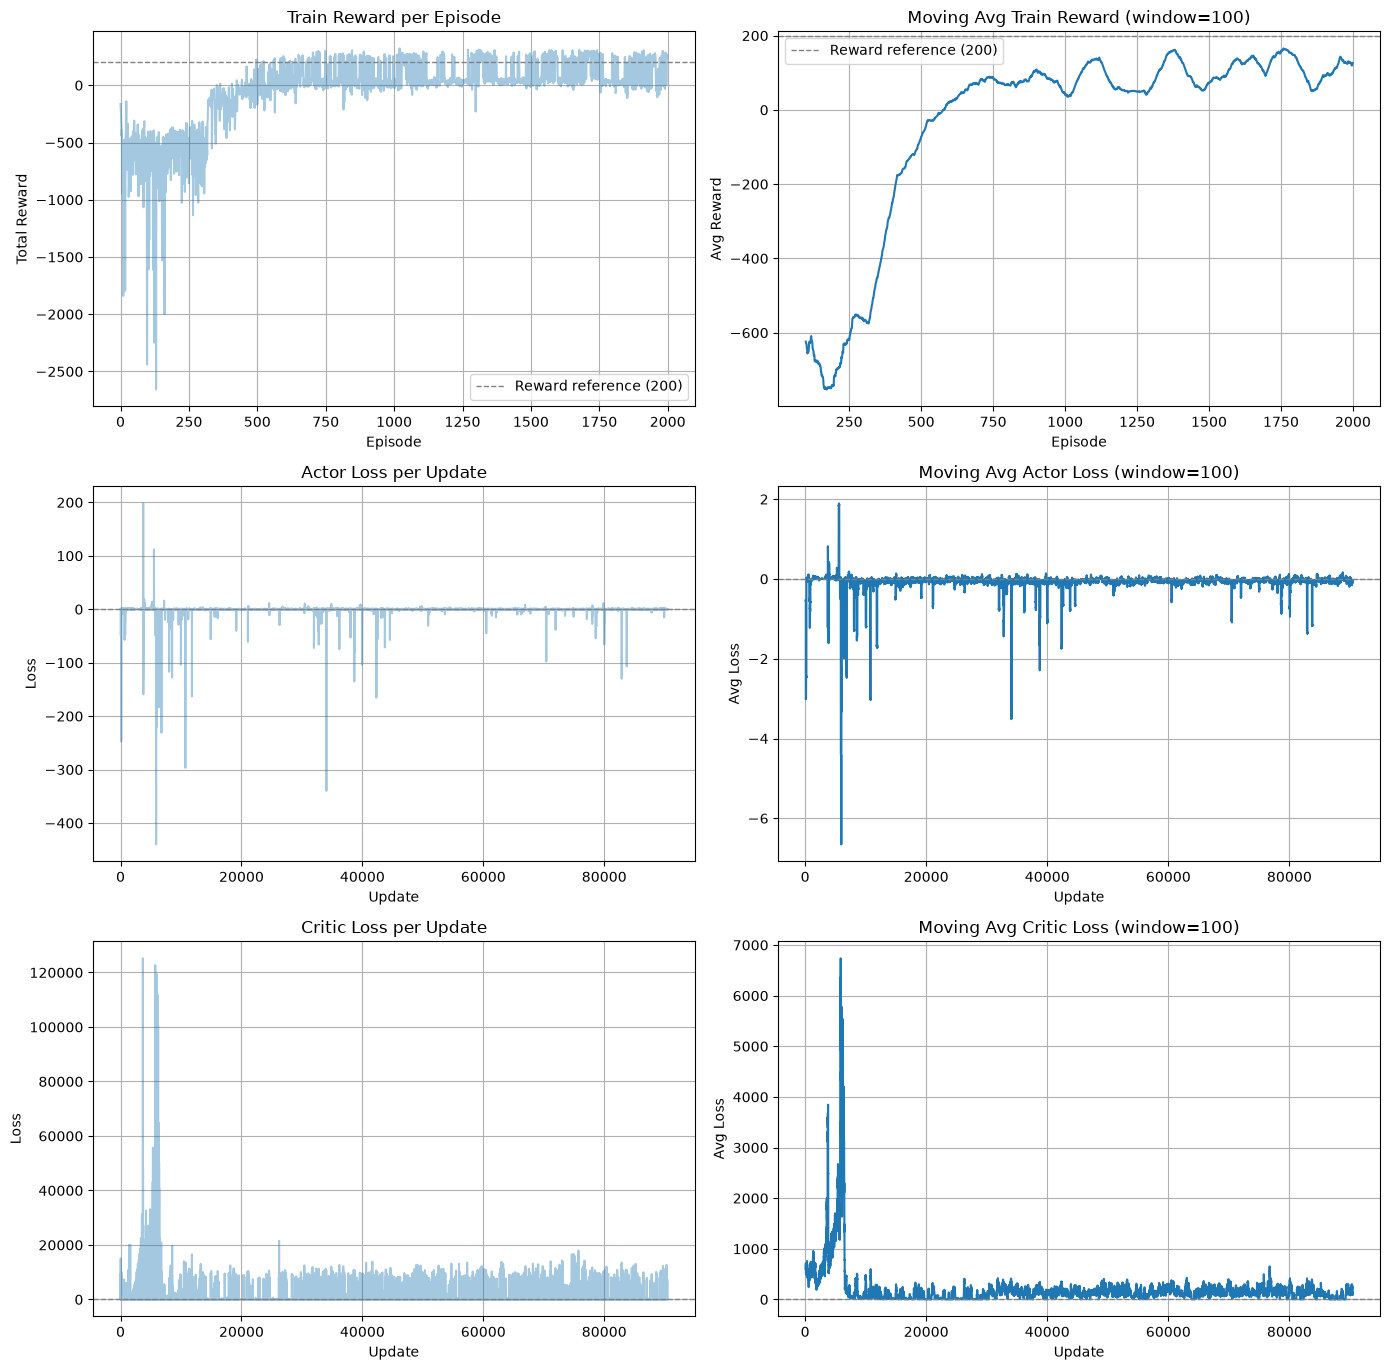


Testing agent...
Test Episode 1: 234.58
Test Episode 2: 254.15
Test Episode 3: 288.99
Test Episode 4: 279.79
Test Episode 5: 283.09


In [12]:
if __name__ == "__main__":

    # Set random seeds for reproducibility
    seed = 30
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    agent, rewards, actor_losses, critic_losses = train_agent(
        episodes=2000,
        rollout_len=5,
        lr=7e-4,
        gamma=0.99,
        gae_lambda=0.95,
        entropy_beta=0.01,
        seed=seed,
    )

    env_id = "LunarLander-v3"
    print(f"\nFinal avg (last 100): {np.mean(rewards[-100:]):.2f}")
    print(f"Max reward: {max(rewards):.2f}")

    solve_line = 200
    plot_results(rewards, actor_losses=actor_losses, critic_losses=critic_losses)

    print("\nTesting agent...")
    test_agent(agent, env_id=env_id, episodes=5, render=True)